In [11]:
#%pip install matplotlib seaborn

In [12]:
# import sys
# !{sys.executable} -m pip install matplotlib seaborn

In [14]:
import pandas as pd
date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']

listings_raw = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)
listings = listings_raw.copy()

listings.shape
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 4574 entries, 0 to 4573
Data columns (total 73 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            4574 non-null   int64         
 1   listing_url                                   4574 non-null   str           
 2   scrape_id                                     4574 non-null   int64         
 3   last_scraped                                  4574 non-null   datetime64[us]
 4   source                                        1704 non-null   str           
 5   name                                          4574 non-null   str           
 6   description                                   4519 non-null   str           
 7   picture_url                                   4574 non-null   str           
 8   host_id                                       4574 non-null   int64         
 9

## Setup Visualization:
1) import matplot from matplotlib
2) import seaborn
3) setup theme

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

Task1:
How many listings(count) for range of reviews:
1) in x axis list range of reviews
2) in y axis number of listings
3) Use histogram chart type
4) listings['number_of_reviews]

(array([3.297e+03, 5.250e+02, 2.160e+02, 1.210e+02, 7.700e+01, 6.400e+01,
        5.100e+01, 4.300e+01, 3.200e+01, 2.400e+01, 2.200e+01, 1.700e+01,
        9.000e+00, 1.100e+01, 1.100e+01, 1.200e+01, 9.000e+00, 4.000e+00,
        6.000e+00, 5.000e+00, 5.000e+00, 2.000e+00, 1.000e+00, 0.000e+00,
        3.000e+00, 1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 2.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([   0.  ,   25.86,   51.72,   77.58,  103.44,  129.3 ,  155.16,
         181.02,  206.88,  232.74,  258.6 ,  284.46,  310.32,  336.18,
         362.04,  387.9 ,  413.76,  439.62,  465.48,  491.34,  517.2 ,
         543.06,  568.92,  594.78,  620.64,  646.5 ,  672.36,  698.22,
         724.08,  749.94,  775.8 ,  801.66,  827.52,  853.38,  879.24,
         905.1 ,  930

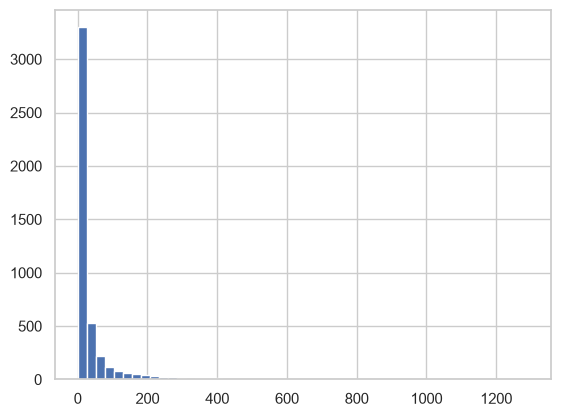

In [18]:
fig,ax = plt.subplots()
ax.hist(listings['number_of_reviews'].dropna(),bins=50)


1293


Text(0, 0.5, 'number of listings')

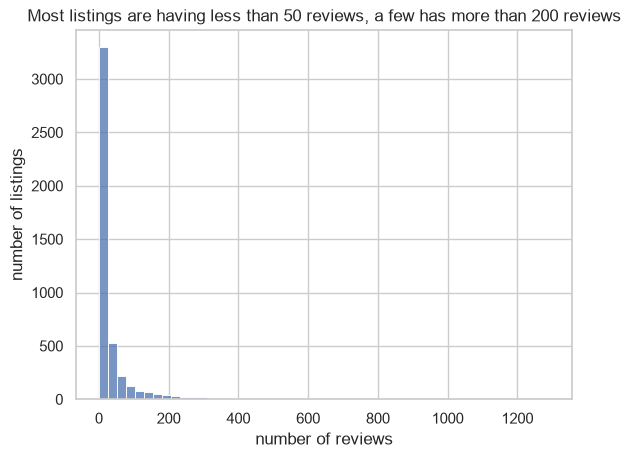

In [23]:
fig, ax = plt.subplots()
sns.histplot(listings,x='number_of_reviews',bins=50,ax=ax)
# Max review (the x axis extension)
print(listings['number_of_reviews'].max())
ax.set_title('Most listings are having less than 50 reviews, a few has more than 200 reviews')
ax.set_xlabel('number of reviews')
ax.set_ylabel('number of listings')


Observation of above:
Few listings has more than 3000 reviews
most of the listings has less than 500 reviews
But this does not say about mean or typical listing reviews

Task2:
mean, median, iqr,upper fence, draw histogram differenciate with different colors

36.0 9.0 2.0 29.0 69.5
69.5 582


Text(0, 0.5, 'number of listings')

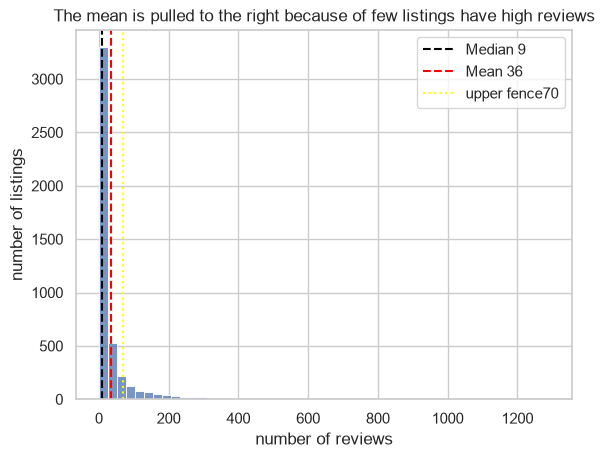

In [ ]:
mean = listings['number_of_reviews'].mean().round(0)
median = listings['number_of_reviews'].median()
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
print(mean,median,q1,q3,upper)

listings['reviews_outlier'] = listings['number_of_reviews'] > upper
print(upper,listings['reviews_outlier'].sum())

fig, ax = plt.subplots()
sns.histplot(listings,x='number_of_reviews',bins=50,ax=ax
             )
ax.axvline(median,color='black',linestyle='--',label=f'Median {median:,.0f}')
ax.axvline(mean,color='red',linestyle='--',label=f'Mean {mean:,.0f}')
ax.axvline(upper,color='yellow',linestyle=':',label=f'upper fence {upper:,.0f}')
ax.legend()

ax.set_title('The mean is pulled to the right because of few listings have high reviews')
ax.set_xlabel('number of reviews')
ax.set_ylabel('number of listings')
